# BGE-Large Text Embedding Pipeline + CNN Fusion

**Pipeline overview:**
1. Upload reef report ZIPs + CNN embeddings CSV
2. Extract text from all PDFs (PyMuPDF + Tesseract OCR for scanned)
3. Chunk text → embed with `BAAI/bge-large-en-v1.5` (1024-dim)
4. Mean-pool chunks → one vector per report year
5. Align to daily CNN embeddings by year
6. Concatenate [256-dim CNN ‖ 1024-dim BGE] → 1280-dim fused vector
7. Save `fused_embeddings_daily.csv` + `.npy`

**Expected output shape:** `(2642, 1283)` — date, split, label + 1280 features

---
## Step 1 — Install dependencies

In [1]:
%%capture
!pip install pymupdf sentence-transformers pytesseract Pillow pandas numpy tqdm
!apt-get install -y tesseract-ocr > /dev/null 2>&1
print("✅ Dependencies installed")

---
## Step 2 — Upload your files

Run each cell and click **Choose Files** when the upload button appears.

In [2]:
from google.colab import files
import os

print("Upload the 3 ZIP files: AIMS_Reports_GBR.zip, MMP_Water_Quality.zip, Reef_Updates_Reports.zip")
print("You can select all 3 at once.")
uploaded_zips = files.upload()

for fname in uploaded_zips:
    print(f"  ✅ Received: {fname}  ({len(uploaded_zips[fname]):,} bytes)")

Upload the 3 ZIP files: AIMS_Reports_GBR.zip, MMP_Water_Quality.zip, Reef_Updates_Reports.zip
You can select all 3 at once.


In [3]:
print("Upload CNN embeddings CSV: cnn_embeddings_daily.csv")
uploaded_csv = files.upload()

for fname in uploaded_csv:
    print(f"  ✅ Received: {fname}  ({len(uploaded_csv[fname]):,} bytes)")

Upload CNN embeddings CSV: cnn_embeddings_daily.csv


Saving cnn_lstm_dropout_best.pth to cnn_lstm_dropout_best.pth
  ✅ Received: cnn_lstm_dropout_best.pth  (7,124,664 bytes)


### Please re-upload the correct CNN embeddings CSV file.

It appears that `cnn_embeddings_daily.csv` was not uploaded in the previous step, or a `.pth` file was uploaded instead. Please use the cell below to upload the correct CSV file.

In [11]:
from google.colab import files
import os

# Clear previously uploaded files from the 'uploaded_csv' variable
# and prompt for the correct file.
print("Please upload 'cnn_embeddings_daily.csv' again.")
uploaded_csv = files.upload()

csv_files = [f for f in uploaded_csv.keys() if f.endswith(".csv")]

if not csv_files:
    print("⚠️ No CSV file was uploaded. Please make sure to upload 'cnn_embeddings_daily.csv'.")
else:
    for fname in uploaded_csv:
        print(f"  ✅ Received: {fname}  ({len(uploaded_csv[fname]):,} bytes)")
    print("\n✅ Successfully re-uploaded CNN embeddings CSV. You can now proceed to the next cells.")


Please upload 'cnn_embeddings_daily.csv' again.


Saving cnn_embeddings_daily.csv to cnn_embeddings_daily.csv
  ✅ Received: cnn_embeddings_daily.csv  (7,151,535 bytes)

✅ Successfully re-uploaded CNN embeddings CSV. You can now proceed to the next cells.


---
## Step 3 — Extract ZIPs and inventory PDFs

In [4]:
import zipfile, re
from pathlib import Path

DATA_DIR = Path("reef_data")
DATA_DIR.mkdir(exist_ok=True)

SOURCE_MAP = {
    "AIMS_Reports_GBR.zip":   "AIMS",
    "MMP_Water_Quality.zip":  "MMP",
    "Reef_Updates_Reports.zip": "Reef",
}

# Get all actual zip files present in the current working directory
# This is more robust than relying solely on `uploaded_zips` which can sometimes be empty.
actual_zip_files_in_content = [f for f in Path('.').glob('*.zip')]

for zip_name_from_source_map, source_key in SOURCE_MAP.items():
    actual_file_to_extract = None
    for actual_file_path in actual_zip_files_in_content:
        # Normalize the actual file's name (replace spaces with underscores) to match SOURCE_MAP key for comparison
        normalized_actual_filename = actual_file_path.name.replace(' ', '_')
        if normalized_actual_filename == zip_name_from_source_map:
            actual_file_to_extract = actual_file_path
            break

    if actual_file_to_extract is None:
        print(f"  ⚠️  {zip_name_from_source_map} not found in available files — skipping")
        continue

    out_dir = DATA_DIR / source_key
    out_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(actual_file_to_extract, 'r') as z: # Use the full path to the actual file
        z.extractall(out_dir)
    print(f"  ✅ Extracted {zip_name_from_source_map} → {out_dir}")

# Inventory all PDFs
all_pdfs = list(DATA_DIR.rglob("*.pdf"))
print(f"\nTotal PDFs found: {len(all_pdfs)}")
for p in all_pdfs:
    print(f"  {p.parent.parent.name}/{p.name}")

  ✅ Extracted AIMS_Reports_GBR.zip → reef_data/AIMS
  ✅ Extracted MMP_Water_Quality.zip → reef_data/MMP
  ✅ Extracted Reef_Updates_Reports.zip → reef_data/Reef

Total PDFs found: 15
  MMP/Marine Monitoring Program Annual Report Water Quality Monitoring 2022-23.pdf
  MMP/MMP Water Quality Report 2023-24.pdf
  MMP/MMP WQ AIMS JCU report 2019_2020_FINAL.pdf
  MMP/FINAL_Synthesis Report 2024-25_v2.pdf
  MMP/Marine Monitoring Program Annual Report2021-22 Inshore Water Quality monitoring.pdf
  MMP/Marine-Monitoring-Program-Annual-Report-Inshore-Water-Quality-Monitoring-2020-21.pdf
  MMP/MMP-Ann-Report-Water-Quality-2018-19.pdf
  Reef/reef-health-updates.pdf
  Reef/past-reef-health-updates.pdf
  AIMS/AIMS Long Term Monitoring Program Annual Summary Report on Coral Reef Condition (GBR) 2020-2021_July2021.pdf
  AIMS/AIMS_LTMP_Report_on GBR_coral_status_2021_2022_040822F3.pdf
  AIMS/AIMS_LTMP_AnnualSummaryReport_2019-20_Aug21_2020(2).pdf
  AIMS/AIMS_LTMP_Report_GBR_coral_status_2022_2023_9August

---
## Step 4 — Extract text from PDFs

- Text-layer PDFs → PyMuPDF direct extraction (fast)
- Scanned PDFs (0 fonts) → Tesseract OCR at 150 DPI (~35 min for the 338-page one)

In [5]:
import fitz          # PyMuPDF
import pytesseract
from PIL import Image
from tqdm.notebook import tqdm

def clean_text(text: str) -> str:
    text = re.sub(r'[^\x09\x0A\x20-\x7E\x80-\xFF]', ' ', text)
    text = re.sub(r'[ \t]{2,}', ' ', text)
    text = re.sub(r'\n{3,}', '\n\n', text)
    lines = [l for l in text.splitlines()
             if not re.fullmatch(r'\s*\d{1,4}\s*', l)]
    return '\n'.join(lines).strip()

def has_text_layer(doc: fitz.Document, sample: int = 8) -> bool:
    n = min(sample, len(doc))
    hits = sum(1 for i in range(n)
               if len(doc[i].get_text("text").strip()) > 40)
    return (hits / n) >= 0.15

def ocr_page(page: fitz.Page, dpi: int = 150) -> str:
    mat = fitz.Matrix(dpi / 72, dpi / 72)
    pix = page.get_pixmap(matrix=mat, alpha=False)
    img = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)
    return clean_text(pytesseract.image_to_string(img, config="--oem 3 --psm 6"))

def extract_pdf_text(pdf_path: Path) -> tuple[str, str]:
    """Returns (full_text, method). method is 'text_layer' or 'ocr'."""
    doc = fitz.open(str(pdf_path))
    if has_text_layer(doc):
        pages = [clean_text(doc[i].get_text("text")) for i in range(len(doc))]
        method = "text_layer"
    else:
        pages = []
        print(f"    ⚙️  OCR mode for {pdf_path.name} ({len(doc)} pages) — this will take a while...")
        for i in tqdm(range(len(doc)), desc="OCR", leave=False):
            pages.append(ocr_page(doc[i]))
        method = "ocr"
    doc.close()
    return "\n\n".join(pages), method

print("Functions defined ✅")

Functions defined ✅


In [6]:
def extract_year(filename: str) -> int | None:
    """Pull the first 20xx year from a filename."""
    m = re.search(r'20(\d{2})', filename)
    return int(m.group(0)) if m else None

# Extract text from all PDFs
# Structure: {year: [text_chunks_from_all_reports_that_year]}
year_texts: dict[int, list[str]] = {}
pdf_log = []

for pdf_path in tqdm(all_pdfs, desc="Extracting PDFs"):
    year = extract_year(pdf_path.name)
    if year is None:
        # Try parent folder name
        year = extract_year(str(pdf_path))

    source = pdf_path.parts[-3] if len(pdf_path.parts) >= 3 else "Unknown"

    text, method = extract_pdf_text(pdf_path)
    word_count = len(text.split())

    if year:
        year_texts.setdefault(year, []).append(text)

    pdf_log.append({
        "pdf": pdf_path.name, "source": source,
        "year": year, "words": word_count, "method": method
    })
    print(f"  {'✅' if year else '⚠️ no year'} {pdf_path.name[:55]:<55} "
          f"year={year}  {word_count:>7,}w  [{method}]")

print(f"\nYears with reports: {sorted(year_texts.keys())}")

Extracting PDFs:   0%|          | 0/15 [00:00<?, ?it/s]

  ✅ Marine Monitoring Program Annual Report Water Quality M year=2022   90,346w  [text_layer]
  ✅ MMP Water Quality Report 2023-24.pdf                    year=2023   93,679w  [text_layer]
  ✅ MMP WQ AIMS JCU report 2019_2020_FINAL.pdf              year=2019   74,793w  [text_layer]
  ✅ FINAL_Synthesis Report 2024-25_v2.pdf                   year=2024   16,584w  [text_layer]
  ✅ Marine Monitoring Program Annual Report2021-22 Inshore  year=2021   90,024w  [text_layer]
    ⚙️  OCR mode for Marine-Monitoring-Program-Annual-Report-Inshore-Water-Quality-Monitoring-2020-21.pdf (338 pages) — this will take a while...


OCR:   0%|          | 0/338 [00:00<?, ?it/s]

  ✅ Marine-Monitoring-Program-Annual-Report-Inshore-Water-Q year=2020  126,205w  [ocr]
  ✅ MMP-Ann-Report-Water-Quality-2018-19.pdf                year=2018   87,061w  [text_layer]
  ⚠️ no year reef-health-updates.pdf                                 year=None    7,380w  [text_layer]
  ⚠️ no year past-reef-health-updates.pdf                            year=None   66,156w  [text_layer]
  ✅ AIMS Long Term Monitoring Program Annual Summary Report year=2020    4,984w  [text_layer]
  ✅ AIMS_LTMP_Report_on GBR_coral_status_2021_2022_040822F3 year=2021    4,636w  [text_layer]
  ✅ AIMS_LTMP_AnnualSummaryReport_2019-20_Aug21_2020(2).pdf year=2019    3,862w  [text_layer]
  ✅ AIMS_LTMP_Report_GBR_coral_status_2022_2023_9August2023 year=2022    4,941w  [text_layer]
  ✅ AIMS_LTMP_Report_GBR_coral_status_2024_2025_final_web.p year=2024    7,192w  [text_layer]
  ✅ AIMS_LTMP_Report_GBR_coral_status_2023_2024_final.pdf   year=2023    6,229w  [text_layer]

Years with reports: [2018, 2019, 2020, 2021, 202

---
## Step 5 — Chunk text per year

Split each year's combined text into 500-word chunks with 50-word overlap.

In [7]:
CHUNK_SIZE    = 500   # words
CHUNK_OVERLAP = 50
MIN_CHUNK_LEN = 60

def chunk_text(text: str, chunk_size: int = CHUNK_SIZE,
               overlap: int = CHUNK_OVERLAP) -> list[str]:
    words = text.split()
    chunks, i = [], 0
    while i < len(words):
        chunk = ' '.join(words[i : i + chunk_size])
        if len(words[i : i + chunk_size]) >= MIN_CHUNK_LEN:
            chunks.append(chunk)
        i += (chunk_size - overlap)
    return chunks

# Build per-year chunk lists
year_chunks: dict[int, list[str]] = {}
for year, texts in sorted(year_texts.items()):
    combined = "\n\n".join(texts)
    chunks   = chunk_text(combined)
    year_chunks[year] = chunks
    print(f"  Year {year}: {len(texts)} report(s) → {len(combined.split()):>7,} words → {len(chunks):>4} chunks")

  Year 2018: 1 report(s) →  87,061 words →  194 chunks
  Year 2019: 2 report(s) →  78,655 words →  175 chunks
  Year 2020: 2 report(s) → 131,189 words →  292 chunks
  Year 2021: 2 report(s) →  94,660 words →  211 chunks
  Year 2022: 2 report(s) →  95,287 words →  212 chunks
  Year 2023: 2 report(s) →  99,908 words →  222 chunks
  Year 2024: 2 report(s) →  23,776 words →   53 chunks


---
## Step 6 — Load BGE-large and embed

`BAAI/bge-large-en-v1.5` — 1024-dim, ~1.3GB download.  
We mean-pool all chunk embeddings per year → one 1024-dim vector per year.

In [8]:
from sentence_transformers import SentenceTransformer
import numpy as np

print("Loading BAAI/bge-large-en-v1.5 (~1.3GB) ...")
bge_model = SentenceTransformer("BAAI/bge-large-en-v1.5")
print(f"✅ Model loaded — embedding dim: {bge_model.get_sentence_embedding_dimension()}")

Loading BAAI/bge-large-en-v1.5 (~1.3GB) ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

✅ Model loaded — embedding dim: 1024


/tmp/ipykernel_926/3143825012.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"✅ Model loaded — embedding dim: {bge_model.get_sentence_embedding_dimension()}")


In [9]:
# BGE-large works best with this prefix for passage embedding
BGE_PREFIX = "Represent this document for retrieval: "

year_embeddings: dict[int, np.ndarray] = {}   # year → 1024-dim vector

for year, chunks in tqdm(sorted(year_chunks.items()), desc="Embedding years"):
    # Prepend BGE prefix to each chunk
    prefixed = [BGE_PREFIX + c for c in chunks]

    # Embed all chunks for this year
    embs = bge_model.encode(
        prefixed,
        batch_size=32,
        normalize_embeddings=True,   # L2 normalise → cosine via dot product
        show_progress_bar=True
    )

    # Mean-pool → single vector per year, then re-normalise
    year_vec = embs.mean(axis=0)
    year_vec = year_vec / np.linalg.norm(year_vec)
    year_embeddings[year] = year_vec
    print(f"  Year {year}: {len(chunks)} chunks → pooled to {year_vec.shape}")

print(f"\n✅ BGE embeddings ready for {len(year_embeddings)} years: {sorted(year_embeddings.keys())}")

Embedding years:   0%|          | 0/7 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

  Year 2018: 194 chunks → pooled to (1024,)


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

  Year 2019: 175 chunks → pooled to (1024,)


...

  Year 2022: 212 chunks → pooled to (1024,)


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

  Year 2023: 222 chunks → pooled to (1024,)


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

  Year 2024: 53 chunks → pooled to (1024,)

✅ BGE embeddings ready for 7 years: [2018, 2019, 2020, 2021, 2022, 2023, 2024]


---
## Step 7 — Align BGE embeddings to daily CNN embeddings

**Strategy:** each daily row gets the BGE vector for its calendar year.  
For years with no report, we interpolate between the nearest available years.

In [12]:
import pandas as pd

csv_name = [f for f in uploaded_csv.keys() if f.endswith(".csv")][0]
cnn_df = pd.read_csv(csv_name)
cnn_df["date"] = pd.to_datetime(cnn_df["date"])
cnn_df["year"] = cnn_df["date"].dt.year

emb_cols = [c for c in cnn_df.columns if c.startswith("emb_")]
print(f"CNN embeddings: {cnn_df.shape}")
print(f"  Date range : {cnn_df['date'].min().date()} → {cnn_df['date'].max().date()}")
print(f"  CNN dims   : {len(emb_cols)}")
print(f"  Years in data: {sorted(cnn_df['year'].unique())}")
print(f"  Label dist :\n{cnn_df['label'].value_counts().sort_index()}")

CNN embeddings: (2642, 260)
  Date range : 2018-01-01 → 2025-12-31
  CNN dims   : 256
  Years in data: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
  Label dist :
label
0    703
1    677
2    279
3    268
4    715
Name: count, dtype: int64


In [13]:
from scipy.interpolate import interp1d

# Build interpolator across years
available_years = sorted(year_embeddings.keys())
emb_matrix      = np.stack([year_embeddings[y] for y in available_years])  # (n_years, 1024)
BGE_DIM         = emb_matrix.shape[1]

# Linear interpolation per dimension
interp = interp1d(
    available_years, emb_matrix,
    axis=0, kind="linear",
    bounds_error=False,
    fill_value=(emb_matrix[0], emb_matrix[-1])  # clamp at edges
)

# Map each daily row to a BGE vector
daily_years    = cnn_df["year"].values
bge_daily      = interp(daily_years).astype(np.float32)   # (2642, 1024)

# Re-normalise interpolated vectors (interpolation breaks unit norm)
norms          = np.linalg.norm(bge_daily, axis=1, keepdims=True)
bge_daily      = bge_daily / np.clip(norms, 1e-8, None)

print(f"BGE daily matrix shape : {bge_daily.shape}")
print(f"Years covered by reports: {available_years}")
data_years = sorted(cnn_df['year'].unique())
interp_years = [y for y in data_years if y not in available_years]
print(f"Years interpolated      : {interp_years if interp_years else 'none — full coverage'}")

BGE daily matrix shape : (2642, 1024)
Years covered by reports: [2018, 2019, 2020, 2021, 2022, 2023, 2024]
Years interpolated      : [np.int32(2025)]


---
## Step 8 — Concatenate CNN + BGE → fused embeddings

In [20]:
from sklearn.preprocessing import StandardScaler

CNN_DIM   = len(emb_cols)
FUSED_DIM = CNN_DIM + BGE_DIM

cnn_matrix  = cnn_df[emb_cols].values.astype(np.float32)   # (2642, 256)

# Scale CNN and BGE blocks separately
cnn_scaled = StandardScaler().fit_transform(cnn_matrix)
bge_scaled = StandardScaler().fit_transform(bge_daily)

fused_matrix = np.concatenate([cnn_scaled, bge_scaled], axis=1)  # (2642, 1280)

print(f"CNN matrix   : {cnn_matrix.shape} (original)")
print(f"BGE daily    : {bge_daily.shape} (original)")
print(f"CNN scaled   : {cnn_scaled.shape}")
print(f"BGE scaled   : {bge_scaled.shape}")
print(f"Fused matrix : {fused_matrix.shape}  ← 256 scaled CNN + 1024 scaled BGE")

# Quick sanity: check no NaNs
assert not np.isnan(fused_matrix).any(), "NaNs found in fused matrix!"
print("✅ No NaNs detected")

CNN matrix   : (2642, 256) (original)
BGE daily    : (2642, 1024) (original)
CNN scaled   : (2642, 256)
BGE scaled   : (2642, 1024)
Fused matrix : (2642, 1280)  ← 256 scaled CNN + 1024 scaled BGE
✅ No NaNs detected


---
## Step 9 — Save outputs

In [21]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ── 1. NumPy array (features only) ──────────────────────────────────────────
npy_path = OUTPUT_DIR / "fused_embeddings_daily.npy"
np.save(npy_path, fused_matrix)
print(f"✅ Saved .npy  : {npy_path}  {fused_matrix.shape}")

# ── 2. CSV (date + split + label + all 1280 features) ───────────────────────
fused_cols  = ([f"cnn_{i}" for i in range(CNN_DIM)] +
               [f"bge_{i}" for i in range(BGE_DIM)])
fused_df    = pd.DataFrame(fused_matrix, columns=fused_cols)
fused_df.insert(0, "date",  cnn_df["date"].dt.strftime("%Y-%m-%d"))
fused_df.insert(1, "split", cnn_df["split"].values)
fused_df.insert(2, "label", cnn_df["label"].values)

csv_path = OUTPUT_DIR / "fused_embeddings_daily.csv"
fused_df.to_csv(csv_path, index=False)
print(f"✅ Saved .csv  : {csv_path}  {fused_df.shape}")

# ── 3. Metadata JSON ────────────────────────────────────────────────────────
import json, datetime

# Convert NumPy integers to Python integers for JSON serialization
label_dist = {int(k): int(v) for k, v in cnn_df['label'].value_counts().sort_index().to_dict().items()}
split_dist = {str(k): int(v) for k, v in cnn_df['split'].value_counts().to_dict().items()}
interpolated_years_int = [int(y) for y in interp_years]
report_years_int = [int(y) for y in available_years]

meta = {
    "created":        datetime.datetime.now().isoformat(),
    "total_rows":     int(fused_df.shape[0]),
    "total_features": FUSED_DIM,
    "cnn_dim":        CNN_DIM,
    "bge_dim":        BGE_DIM,
    "bge_model":      "BAAI/bge-large-en-v1.5",
    "date_range":     [str(cnn_df['date'].min().date()), str(cnn_df['date'].max().date())],
    "report_years":   report_years_int,
    "interpolated_years": interpolated_years_int,
    "label_distribution": label_dist,
    "split_distribution": split_dist,
    "pdfs_processed": pdf_log,
}
meta_path = OUTPUT_DIR / "fusion_metadata.json"
with open(meta_path, "w") as f:
    json.dump(meta, f, indent=2)
print(f"✅ Saved meta  : {meta_path}")

✅ Saved .npy  : outputs/fused_embeddings_daily.npy  (2642, 1280)
✅ Saved .csv  : outputs/fused_embeddings_daily.csv  (2642, 1283)
✅ Saved meta  : outputs/fusion_metadata.json


---
## Step 10 — Download outputs to your machine

In [22]:
print("Downloading fused_embeddings_daily.npy ...")
files.download(str(npy_path))

print("Downloading fused_embeddings_daily.csv ...")
files.download(str(csv_path))

print("Downloading fusion_metadata.json ...")
files.download(str(meta_path))

print("✅ All downloads triggered")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ All downloads triggered


---
## Step 11 — Quick sanity check on retrieval quality

Cosine similarity between years — reports from the same era should cluster together.

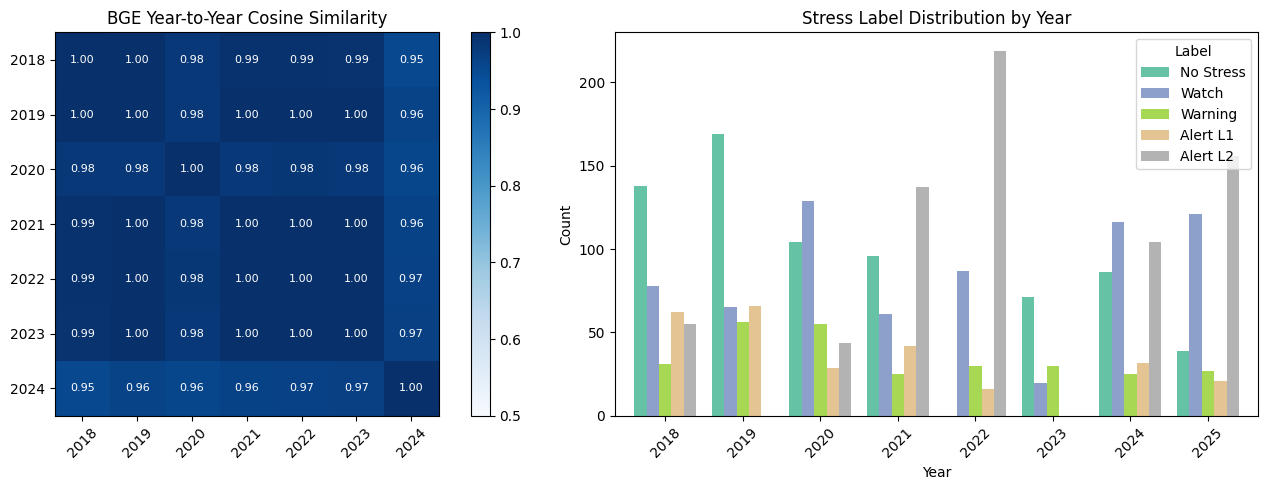

✅ Sanity check plots saved


In [23]:
import matplotlib.pyplot as plt

years   = sorted(year_embeddings.keys())
vecs    = np.stack([year_embeddings[y] for y in years])
sim_mat = vecs @ vecs.T   # cosine sim since vectors are L2-normalised

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Similarity heatmap
im = axes[0].imshow(sim_mat, cmap="Blues", vmin=0.5, vmax=1.0)
axes[0].set_xticks(range(len(years))); axes[0].set_xticklabels(years, rotation=45)
axes[0].set_yticks(range(len(years))); axes[0].set_yticklabels(years)
axes[0].set_title("BGE Year-to-Year Cosine Similarity")
plt.colorbar(im, ax=axes[0])
for i in range(len(years)):
    for j in range(len(years)):
        axes[0].text(j, i, f"{sim_mat[i,j]:.2f}", ha='center', va='center',
                     fontsize=8, color='white' if sim_mat[i,j] > 0.8 else 'black')

# Label distribution per year in CNN data
label_by_year = cnn_df.groupby(['year','label']).size().unstack(fill_value=0)
label_by_year.plot(kind='bar', ax=axes[1], colormap='Set2', width=0.8)
axes[1].set_title("Stress Label Distribution by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Count")
axes[1].legend(title="Label", labels=["No Stress","Watch","Warning","Alert L1","Alert L2"])
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sanity_check.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Sanity check plots saved")

### Save BGE (NLP) embeddings to a separate CSV

If you want a CSV containing only the BGE (NLP) embeddings, you can run the following cell. This will create a file named `bge_embeddings_daily.csv` in the `outputs` directory.

In [24]:
bge_cols = [f"bge_{i}" for i in range(BGE_DIM)]
bge_df = pd.DataFrame(bge_daily, columns=bge_cols)

# Add date, split, and label columns for consistency if needed,
# using cnn_df as the source for these.
bge_df.insert(0, "date", cnn_df["date"].dt.strftime("%Y-%m-%d"))
bge_df.insert(1, "split", cnn_df["split"].values)
bge_df.insert(2, "label", cnn_df["label"].values)

bge_csv_path = OUTPUT_DIR / "bge_embeddings_daily.csv"
bge_df.to_csv(bge_csv_path, index=False)
print(f"✅ Saved BGE embeddings CSV: {bge_csv_path} {bge_df.shape}")

✅ Saved BGE embeddings CSV: outputs/bge_embeddings_daily.csv (2642, 1027)


You can download this new CSV file using the following cell:

In [25]:
print("Downloading bge_embeddings_daily.csv ...")
files.download(str(bge_csv_path))
print("✅ Download triggered")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download triggered


---
## What to do next with `fused_embeddings_daily.csv`

The fused file is a drop-in replacement for your existing `cnn_embeddings_daily.csv`. In your CNN+LSTM notebook, just change the input to load the fused CSV and update the input dimension:

```python
# Before
df = pd.read_csv('cnn_embeddings_daily.csv')   # 256-dim input

# After  
df = pd.read_csv('fused_embeddings_daily.csv') # 1280-dim input
# update your model's first layer: input_size=1280
```

**Tip:** consider training two separate encoders (one CNN head, one BGE head) that merge before the classifier — this lets the model learn different weights for temporal vs. textual signals. Happy to build that if the fused baseline looks promising.